# Machine Learning Model Evaluation

## Objective
Evaluate the performance of machine learning classification models using different evaluation metrics.

## Dataset
Iris Flower Dataset from Scikit-learn.

## Models
1. Logistic Regression
2. Decision Tree Classifier

## Evaluation Metrics
1. Accuracy
2. Precision
3. Recall
4. F1 Score
5. Confusion Matrix

## Workflow
1. Load the Iris dataset.
2. Split the dataset into training and testing sets.
3. Train Logistic Regression and Decision Tree models.
4. Make predictions using both models.
5. Calculate evaluation metrics.
6. Generate confusion matrices.
7. Compare model performance and record observations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Iris dataset
iris = load_iris()

# Convert dataset into a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df["species"] = iris.target

# Display first five rows
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
# Input features
X = df.drop("species", axis=1)

# Target variable
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [5]:
# Train Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

# Train Decision Tree
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [6]:
# Predictions from Logistic Regression
y_pred_log = log_model.predict(X_test)

# Predictions from Decision Tree
y_pred_tree = tree_model.predict(X_test)

print("Predictions generated successfully!")
print("Logistic Regression predictions:", y_pred_log)
print("Decision Tree predictions:", y_pred_tree)

Predictions generated successfully!
Logistic Regression predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]
Decision Tree predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [7]:
metrics_data = []

for model_name, y_pred in [
    ("Logistic Regression", y_pred_log),
    ("Decision Tree", y_pred_tree)
]:
    metrics_data.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1 Score": f1_score(y_test, y_pred, average="weighted")
    })

evaluation_df = pd.DataFrame(metrics_data)

display(evaluation_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9667,0.9697,0.9667,0.9666
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


Logistic Regression Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


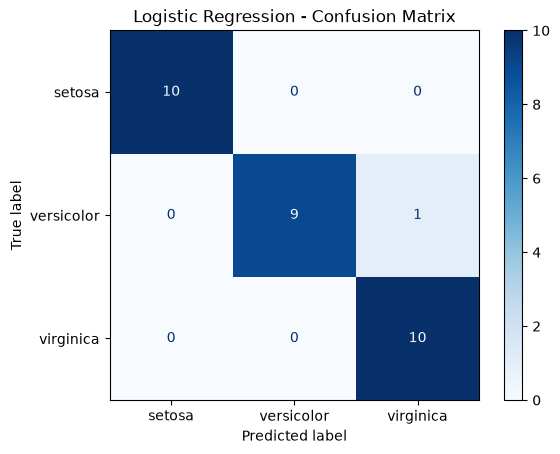

In [8]:
# Confusion Matrix for Logistic Regression
cm_log = confusion_matrix(y_test, y_pred_log)

print("Logistic Regression Confusion Matrix:")
print(cm_log)

ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=iris.target_names
).plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

Decision Tree Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


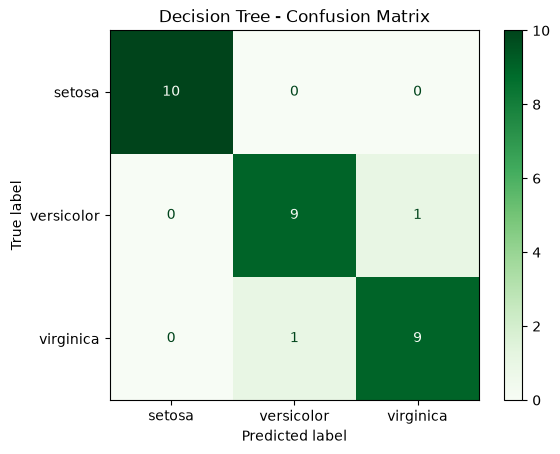

In [10]:
# Confusion Matrix for Decision Tree
cm_tree = confusion_matrix(y_test, y_pred_tree)

print("Decision Tree Confusion Matrix:")
print(cm_tree)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=iris.target_names
).plot(cmap="Greens")

plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [11]:
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred_log,
    target_names=iris.target_names
))

print("\nDECISION TREE - CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred_tree,
    target_names=iris.target_names
))

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


DECISION TREE - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## Understanding Evaluation Metrics

### 1. Accuracy
Accuracy measures the percentage of total predictions that are correct.

### 2. Precision
Precision measures how many of the samples predicted as a particular class were actually correct.

### 3. Recall
Recall measures how many actual samples of a particular class were correctly identified.

### 4. F1 Score
F1 Score is the harmonic mean of Precision and Recall. It balances both metrics.

### 5. Confusion Matrix
A Confusion Matrix shows correct and incorrect predictions for each class.

## Most Useful Metric for the Iris Dataset

Accuracy is a useful primary metric for the Iris dataset because all three flower classes have an equal number of samples.

However, Precision, Recall, F1 Score, and the Confusion Matrix are also important because they provide more detailed information about the model's performance for each flower class.

Therefore, Accuracy can be used as the main overall measure, supported by the other evaluation metrics.

## Conclusion

In this project, I evaluated Logistic Regression and Decision Tree classification models using the Iris dataset.

I calculated Accuracy, Precision, Recall, and F1 Score for both models. I also generated Confusion Matrices and Classification Reports to understand their performance.

This project helped me understand how to evaluate machine learning classification models and compare their performance using different evaluation metrics.